# 14 — 2026-10-26: full run with LLaVA-Video-7B-Qwen2 (transformers conversion `Isotr0py/LLaVA-Video-7B-Qwen2-hf`)

All 598 questions in six conditions (Q_noE, Q, T, T_told, VT, VTmis), options in a random order, and two follow-up questions after each answer (a free-form explanation and an evidence question). Settings in `configs/2026-10-26_llava_video_full.toml`, results in `outputs/2026-10-26_llava_video_full/`; `prob_*` and `answer` use the original option letters, `option_order` and `answer_shown` what the model saw.

In [1]:
N_QUESTIONS = None  # None = all 598 questions
CONDITIONS = None  # None = all conditions in the config

In [2]:
import sys, json, random, time, tomllib
from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import llava_video as mdl

CFG_PATH = ROOT / "configs/2026-10-26_llava_video_full.toml"
CFG = tomllib.loads(CFG_PATH.read_text())
CONDITIONS = CONDITIONS or CFG["conditions"]
assert set(CONDITIONS) <= set(CFG["conditions"]), CONDITIONS
EXP_DIR = ROOT / "outputs" / CFG["experiment"]
EXP_DIR.mkdir(parents=True, exist_ok=True)
OUT = EXP_DIR / "results.jsonl"

all_questions = pd.read_parquet(ROOT / "data-private/processed/emotion_questions.parquet")
questions = all_questions.head(N_QUESTIONS)
print(f"{len(questions)} questions, conditions {CONDITIONS} -> {OUT.relative_to(ROOT)}")

598 questions, conditions ['Q_noE', 'Q', 'T', 'T_told', 'VT', 'VTmis'] -> outputs/2026-10-26_llava_video_full/results.jsonl


## Mismatched clips

Each question gets the clip of an Emotions question from a different film with the closest clip length.

In [3]:
mismatch = {}
for q in all_questions.itertuples():
    other = all_questions[all_questions.movie_title != q.movie_title]
    gap = (other.focused_duration_s - q.focused_duration_s).abs()
    mismatch[q.question_id] = other.loc[gap.idxmin()]

pairs = pd.DataFrame({"question_id": list(mismatch),
                      "clip_s": all_questions.focused_duration_s.values,
                      "mis_question_id": [m.question_id for m in mismatch.values()],
                      "mis_movie_title": [m.movie_title for m in mismatch.values()],
                      "mis_clip_s": [m.focused_duration_s for m in mismatch.values()]})
pairs.to_csv(EXP_DIR / "mismatch_pairs.csv", index=False)
print("median |clip length difference| (s):", round((pairs.clip_s - pairs.mis_clip_s).abs().median(), 2))
pairs.head().round(1)

median |clip length difference| (s): 0.05


,question_id,clip_s,mis_question_id,mis_movie_title,mis_clip_s
0,FH-76,21.3,x40a1,MAN TO MAN,21.2
1,97rJU,47.5,ZNAaV,DUSSELDORF,47.6
2,cP4lM,294.0,hjEci,POMMEL,291.1
3,XESWo,55.0,iBIiz,COOL FOR FIVE SECONDS,55.1
4,6p7dK,21.4,kREcQ,THE REFEREE,21.4


## Option order

In [4]:
SHOWN = ["A", "B", "C", "D", "E"]


def option_order(question_id, with_e=True):
    order = ["A", "B", "C", "D", "E"]
    random.Random(f"{CFG['shuffle_seed']}-{question_id}").shuffle(order)
    return order if with_e else [x for x in order if x != "E"]


EVIDENCE = CFG["evidence_options"]


def evidence_order(question_id):
    order = list(EVIDENCE)
    random.Random(f"{CFG['shuffle_seed']}-{question_id}-evidence").shuffle(order)
    return order


def evidence_prompt(order):
    options = [f"{shown}. {EVIDENCE[name]}" for shown, name in zip(SHOWN, order)]
    return CFG["evidence_question"] + "\n" + "\n".join(options) + "\n\nAnswer with the option's letter only."


e_position = pd.Series([SHOWN[option_order(qid).index("E")] for qid in all_questions.question_id])
print('"Cannot tell" shown as:', e_position.value_counts().sort_index().to_dict())

"Cannot tell" shown as: {'A': 102, 'B': 106, 'C': 119, 'D': 138, 'E': 133}


## Load the model

In [5]:
processor, model = mdl.load(CFG["model_revision"])
print("device:", model.device)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/765 [00:00<?, ?it/s]

device: cuda:0


## Show the exact prompts for the first question

In [6]:
first = questions.iloc[0]
order = option_order(first.question_id)
print("option order:", "".join(order))
for title, text in [("Q_noE", mdl.build_prompt(first, with_transcript=False, order=option_order(first.question_id, with_e=False))),
                    ("Q", mdl.build_prompt(first, with_transcript=False, option_e=CFG["option_e"], order=order)),
                    ("T_told", CFG["told_note"] + "\n\n" + mdl.build_prompt(first, option_e=CFG["option_e"], order=order)),
                    ("T, VT, VTmis", mdl.build_prompt(first, option_e=CFG["option_e"], order=order))]:
    print(f"===== {title}")
    print(mdl.make_inputs(processor, None, text)[1])
print("===== branch A: free-form explanation (T)")
print(mdl.make_inputs(processor, None, text, followup=("A", CFG["explain_prompt"]))[1])
print("===== branch B: evidence question (T)")
print(mdl.make_inputs(processor, None, text, followup=("A", evidence_prompt(evidence_order(first.question_id))))[1])

option order: CBEDA
===== Q_noE
<|im_start|>user
Question: How does the man feel about knocking on the door?
A. The man expresses annoyance.
B. The man expresses fear that there might not be anyone inside.
C. The man expresses nervousness.
D. The man expresses sadness that he won't come inside.

Answer with the option's letter only.<|im_end|>
<|im_start|>assistant

===== Q
<|im_start|>user
Question: How does the man feel about knocking on the door?
A. The man expresses annoyance.
B. The man expresses fear that there might not be anyone inside.
C. Cannot tell from the given information.
D. The man expresses nervousness.
E. The man expresses sadness that he won't come inside.

Answer with the option's letter only.<|im_end|>
<|im_start|>assistant

===== T_told
<|im_start|>user
A video of this scene exists, but it is not shown to you.

Transcript of the dialogue in the clip:
(no dialogue)

Question: How does the man feel about knocking on the door?
A. The man expresses annoyance.
B. The ma

## Run

In [7]:
done = {(r["question_id"], r["condition"]) for r in map(json.loads, OUT.open())} if OUT.exists() else set()
print(f"{len(done)} results already in {OUT.name}")

for q in tqdm(questions.itertuples(), total=len(questions), unit="question"):
    for condition in CONDITIONS:
        if (q.question_id, condition) in done:
            continue
        t0 = time.time()

        option_e = None if condition == "Q_noE" else CFG["option_e"]
        order = option_order(q.question_id, with_e=condition != "Q_noE")
        shown = SHOWN[:len(order)]
        user_text = mdl.build_prompt(q._asdict(), with_transcript=condition in ["T", "T_told", "VT", "VTmis"],
                                    option_e=option_e, order=order)
        if condition == "T_told":
            user_text = CFG["told_note"] + "\n\n" + user_text

        clip, frames, fps = None, None, None
        if condition == "VT":
            clip = q
        if condition == "VTmis":
            clip = mismatch[q.question_id]
        if clip is not None:
            video = ROOT / "data-private/raw/all_videos" / f"{clip.movie_title}.mp4"
            frames, fps = mdl.sample_frames(video, clip.t_i, clip.t_j, int(clip.n_frames), CFG["max_pixels"])

        inputs, _ = mdl.make_inputs(processor, None, user_text, frames, fps)
        r = mdl.score_options(model, processor, inputs, shown)
        top = r["prob"].index(max(r["prob"]))
        answer_shown, answer = shown[top], order[top]
        t1 = time.time()

        inputs, _ = mdl.make_inputs(processor, None, user_text, frames, fps,
                                   followup=(answer_shown, CFG["explain_prompt"]))
        e = mdl.generate_text(model, processor, inputs, CFG["explain_max_new_tokens"])
        t2 = time.time()

        ev_order = evidence_order(q.question_id)
        inputs, _ = mdl.make_inputs(processor, None, user_text, frames, fps,
                                   followup=(answer_shown, evidence_prompt(ev_order)))
        ev = mdl.score_options(model, processor, inputs, SHOWN[:len(ev_order)])

        row = {"order": q.order, "question_id": q.question_id, "condition": condition,
               **{f"prob_{L}": p for L, p in zip(order, r["prob"])},
               "mass_on_letters": r["mass_on_letters"], "n_input_tokens": r["n_input_tokens"], "answer": answer, "answer_shown": answer_shown, "option_order": "".join(order),
               "explanation": e["text"], "explanation_tokens": e["n_tokens"], "explanation_hit_limit": e["hit_limit"],
               **{f"evidence_prob_{name}": p for name, p in zip(ev_order, ev["prob"])},
               "evidence_answer": ev_order[ev["prob"].index(max(ev["prob"]))],
               "evidence_order": ",".join(ev_order), "evidence_mass_on_letters": ev["mass_on_letters"],
               "score_seconds": round(t1 - t0, 1), "explain_seconds": round(t2 - t1, 1), "evidence_seconds": round(time.time() - t2, 1),
               "video_question_id": None if clip is None else clip.question_id,
               "n_frames": 0 if frames is None else len(frames),
               "max_pixels": CFG["max_pixels"], "model_revision": CFG["model_revision"], "device": str(model.device)}
        with OUT.open("a") as f:
            f.write(json.dumps(row) + "\n")

60 results already in results.jsonl


  0%|          | 0/598 [00:00<?, ?question/s]

qwen-vl-utils using decord to read video.
[transformers] Keyword argument `cap_pixels_per_frame` is not a valid argument for this processor and will be ignored.
[h264 @ 0x5632616f0b00] mmco: unref short failure
[h264 @ 0x5632616f0b00] mmco: unref short failure
[h264 @ 0x5632616f0b00] mmco: unref short failure
[h264 @ 0x5632616f0b00] mmco: unref short failure
[h264 @ 0x5632616f0b00] mmco: unref short failure
[h264 @ 0x5632611b0580] mmco: unref short failure
[h264 @ 0x563261749700] mmco: unref short failure
[h264 @ 0x563261749700] mmco: unref short failure
[h264 @ 0x5632611a4180] mmco: unref short failure
[h264 @ 0x56326275f9c0] mmco: unref short failure
[h264 @ 0x563261a7dac0] mmco: unref short failure
[h264 @ 0x563261a7dac0] mmco: unref short failure
[h264 @ 0x563261541c40] mmco: unref short failure
[h264 @ 0x563261541c40] mmco: unref short failure
[h264 @ 0x5632618242c0] mmco: unref short failure
[h264 @ 0x56326142c800] mmco: unref short failure
[h264 @ 0x56326142c800] mmco: unref sho

## Results so far

In [8]:
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

HIGH_CONFIDENCE = 0.8
FIGURES = EXP_DIR / "figures"
FIGURES.mkdir(exist_ok=True)

keys = pd.read_parquet(ROOT / "data-private/processed/answer_keys.parquet")[["question_id", "correct_answer_key"]]
info = all_questions[["question_id", "movie_title", "question", "cue_visual_any"]]
df = pd.read_json(OUT, lines=True).drop_duplicates(["question_id", "condition"]).merge(keys, on="question_id").merge(info, on="question_id")

n_conditions = df.groupby("question_id").condition.transform("nunique")
df = df[n_conditions == df.condition.nunique()].copy()
conditions = [c for c in CFG["conditions"] if c in set(df.condition)]
print(df.question_id.nunique(), "questions with all of", conditions)

abcd = ["prob_A", "prob_B", "prob_C", "prob_D"]
df["abstain"] = df.answer == "E"
df["p_E"] = df.prob_E.fillna(0)
df["correct"] = df.answer == df.correct_answer_key
df["confidence"] = df[abcd].max(axis=1) / df[abcd].sum(axis=1)
df["confidently_wrong"] = ~df.correct & ~df.abstain & (df.confidence >= HIGH_CONFIDENCE)

598 questions with all of ['Q_noE', 'Q', 'T', 'T_told', 'VT', 'VTmis']


In [9]:
summary = df.groupby("condition").agg(
    n=("correct", "size"),
    accuracy=("correct", "mean"),
    abstain=("abstain", "mean"),
    mean_p_E=("p_E", "mean"),
    confidence=("confidence", "mean"),
    confidently_wrong=("confidently_wrong", "mean"),
    mass_on_letters=("mass_on_letters", "mean"),
    score_seconds=("score_seconds", "mean"),
    explain_seconds=("explain_seconds", "mean"),
    evidence_seconds=("evidence_seconds", "mean"),
).reindex(conditions)
summary.insert(3, "selective_accuracy", df[~df.abstain].groupby("condition").correct.mean())
summary.round(3)

,n,accuracy,abstain,selective_accuracy,mean_p_E,confidence,confidently_wrong,mass_on_letters,score_seconds,explain_seconds,evidence_seconds
condition,,,,,,,,,,,
Q_noE,598,0.413,0.000,0.413,0.000,0.685,0.151,1.0,0.106,0.794,0.011
Q,598,0.304,0.284,0.425,0.277,0.652,0.092,1.0,0.011,0.820,0.012
T,598,0.475,0.137,0.550,0.168,0.684,0.084,1.0,0.015,0.895,0.019
T_told,598,0.482,0.140,0.560,0.176,0.683,0.070,1.0,0.015,0.869,0.019
VT,598,0.472,0.147,0.553,0.187,0.696,0.087,1.0,4.484,3.034,2.242
VTmis,598,0.380,0.247,0.504,0.231,0.665,0.094,1.0,4.482,3.042,2.243


By visual-cue tag:

In [10]:
df.pivot_table(index="condition", columns="cue_visual_any", values=["correct", "abstain", "p_E", "confidently_wrong"],
               aggfunc="mean").reindex(conditions).round(3)

abstain        confidently_wrong        correct           p_E  \
cue_visual_any   False  True              False  True    False  True   False   
condition                                                                      
Q_noE            0.000  0.000             0.196  0.142   0.359  0.423  0.000   
Q                0.217  0.296             0.120  0.087   0.217  0.320  0.232   
T                0.120  0.140             0.054  0.089   0.424  0.484  0.133   
T_told           0.098  0.148             0.033  0.077   0.457  0.486  0.143   
VT               0.130  0.150             0.054  0.093   0.424  0.480  0.167   
VTmis            0.196  0.257             0.130  0.087   0.359  0.383  0.186   

                       
cue_visual_any  True   
condition              
Q_noE           0.000  
Q               0.285  
T               0.174  
T_told          0.182  
VT              0.190  
VTmis           0.239

### Paired comparisons (Wilcoxon)

In [11]:
wide = df.pivot(index="question_id", columns="condition", values=["p_E", "confidence"])
rows = []
for a, b in [("Q", "T"), ("T", "T_told"), ("T", "VT"), ("VT", "VTmis"), ("T", "VTmis")]:
    if a not in conditions or b not in conditions:
        continue
    for measure in ["p_E", "confidence"]:
        diff = wide[measure][b] - wide[measure][a]
        rows.append({"comparison": f"{b} - {a}", "measure": measure, "n": len(diff),
                     "mean_diff": diff.mean(), "median_diff": diff.median(),
                     "p": wilcoxon(diff).pvalue if (diff != 0).any() else None})
pd.DataFrame(rows).round(4)

,comparison,measure,n,mean_diff,median_diff,p
0,T - Q,p_E,598,-0.1091,-0.0568,0.0000
1,T - Q,confidence,598,0.0324,-0.0005,0.0190
2,T_told - T,p_E,598,0.0081,0.0042,0.0000
3,T_told - T,confidence,598,-0.0016,-0.0004,0.6939
4,VT - T,p_E,598,0.0185,0.0053,0.0000
5,VT - T,confidence,598,0.0117,-0.0004,0.2117
6,VTmis - VT,p_E,598,0.0447,0.0156,0.0000
7,VTmis - VT,confidence,598,-0.0310,-0.0149,0.0000
8,VTmis - T,p_E,598,0.0632,0.0280,0.0000
9,VTmis - T,confidence,598,-0.0193,-0.0105,0.0063


### Plot

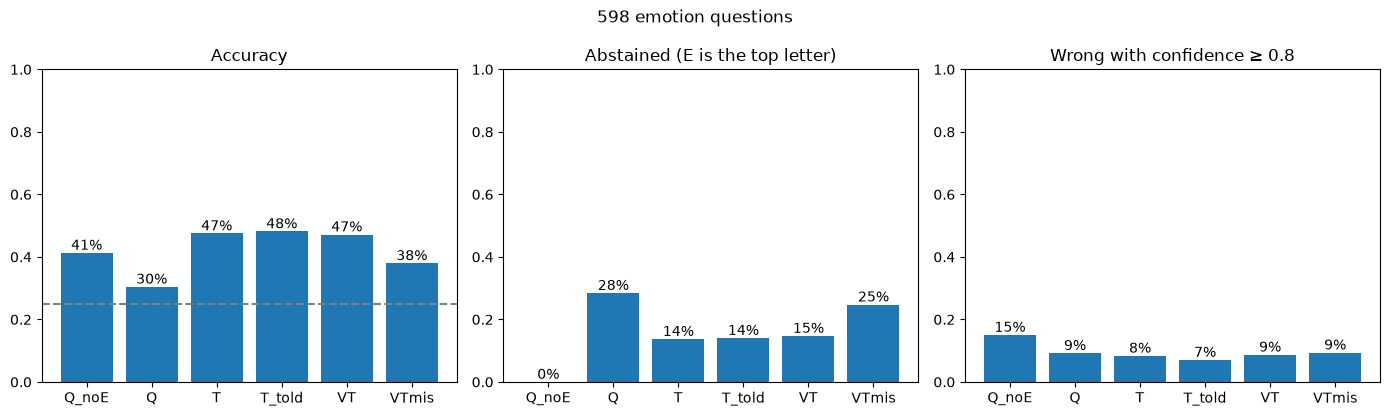

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, col, title in [(axes[0], "accuracy", "Accuracy"),
                       (axes[1], "abstain", "Abstained (E is the top letter)"),
                       (axes[2], "confidently_wrong", f"Wrong with confidence ≥ {HIGH_CONFIDENCE}")]:
    ax.bar(summary.index, summary[col], color="tab:blue")
    for i, value in enumerate(summary[col]):
        ax.text(i, value + 0.01, f"{value:.0%}", ha="center")
    ax.set(title=title, ylim=(0, 1))
axes[0].axhline(0.25, ls="--", c="gray")
fig.suptitle(f"{df.question_id.nunique()} emotion questions")
fig.tight_layout()
fig.savefig(FIGURES / "summary_by_condition.png", dpi=200)
plt.show()

### More plots

In [13]:
import numpy as np

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e2dc"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "axes.titlecolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "axes.axisbelow": True,
                     "font.size": 11, "legend.frameon": False})

def bootstrap_ci(values, n_resamples=2000, seed=0):
    rng = np.random.default_rng(seed)
    values = np.asarray(values, dtype=float)
    means = [rng.choice(values, len(values)).mean() for _ in range(n_resamples)]
    return np.percentile(means, [2.5, 97.5])

def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * (p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5 / (1 + z**2 / n)
    return centre - half, centre + half

df["forced_answer"] = df[abcd].idxmax(axis=1).str[-1]
df["forced_correct"] = df.forced_answer == df.correct_answer_key
df["no_dialogue"] = df.question_id.map(all_questions.set_index("question_id").focused_n_words) == 0
df["outcome"] = np.where(df.abstain, "abstain", np.where(df.correct, "right", "wrong"))
with_e = [c for c in conditions if c != "Q_noE"]

#### 1. Abstention by condition

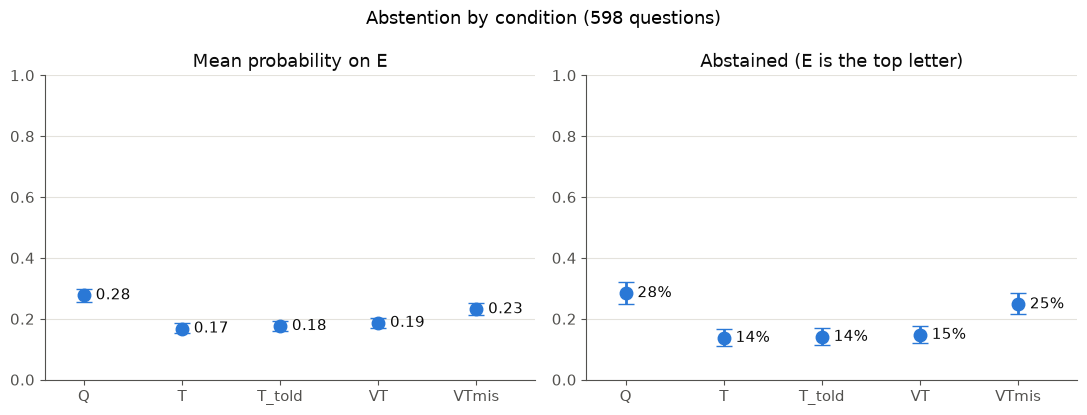

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, title in zip(axes, ["Mean probability on E", "Abstained (E is the top letter)"]):
    for i, condition in enumerate(with_e):
        g = df[df.condition == condition]
        if title.startswith("Mean"):
            value, (lo, hi) = g.p_E.mean(), bootstrap_ci(g.p_E)
        else:
            value, (lo, hi) = g.abstain.mean(), wilson(g.abstain.sum(), len(g))
        ax.errorbar(i, value, yerr=[[value - lo], [hi - value]], fmt="o", ms=9, color=BLUE, capsize=6, lw=2)
        ax.text(i + 0.12, value, f"{value:.2f}" if title.startswith("Mean") else f"{value:.0%}", va="center", color=INK)
    ax.set(xticks=range(len(with_e)), xticklabels=with_e, ylim=(0, 1), xlim=(-0.4, len(with_e) - 0.4), title=title)
fig.suptitle(f"Abstention by condition ({df.question_id.nunique()} questions)")
fig.tight_layout()
fig.savefig(FIGURES / "abstention_by_condition.png", dpi=200)
plt.show()

#### 2. Outcome of every question, by condition

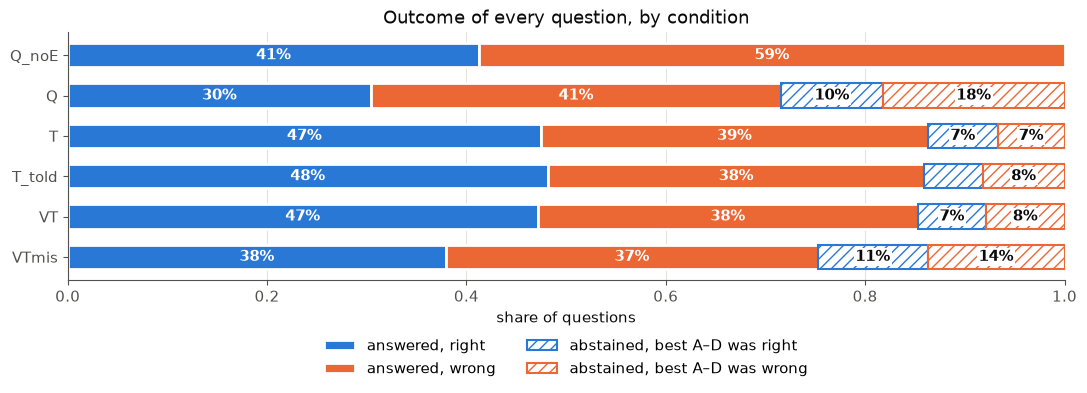

accuracy among answered: {'Q_noE': 0.413, 'Q': 0.425, 'T': 0.55, 'T_told': 0.56, 'VT': 0.553, 'VTmis': 0.504}
forced A-D accuracy:    {'Q_noE': 0.415, 'Q': 0.408, 'T': 0.543, 'T_told': 0.54, 'VT': 0.54, 'VTmis': 0.493}


In [15]:
parts = [("answered, right", ~df.abstain & df.correct, BLUE, None),
         ("answered, wrong", ~df.abstain & ~df.correct, ORANGE, None),
         ("abstained, best A–D was right", df.abstain & df.forced_correct, BLUE, "///"),
         ("abstained, best A–D was wrong", df.abstain & ~df.forced_correct, ORANGE, "///")]

fig, ax = plt.subplots(figsize=(11, 4.2))
rows = np.arange(len(conditions))
left = np.zeros(len(conditions))
for label, mask, color, hatch in parts:
    share = mask.groupby(df.condition).mean().reindex(conditions).values
    hatched = hatch is not None
    keep = share > 0
    ax.barh(rows[keep], share[keep], left=left[keep], color="white" if hatched else color, edgecolor=color if hatched else "white",
            hatch=hatch, linewidth=1.5 if hatched else 2, label=label, height=0.6)
    for y, (x, w) in enumerate(zip(left, share)):
        if w >= 0.06:
            ax.text(x + w / 2, y, f"{w:.0%}", ha="center", va="center", color=INK if hatched else "white",
                    fontweight="bold", bbox=dict(facecolor="white", edgecolor="none", pad=1) if hatched else None)
    left += share
ax.set_yticks(rows, conditions)
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="share of questions", title="Outcome of every question, by condition")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout()
fig.savefig(FIGURES / "outcomes_by_condition.png", dpi=200)
plt.show()

print("accuracy among answered:", df[~df.abstain].groupby("condition").correct.mean().reindex(conditions).round(3).to_dict())
print("forced A-D accuracy:   ", df.groupby("condition").forced_correct.mean().reindex(conditions).round(3).to_dict())

#### 3. Question by question: P(E) with and without the (right) video

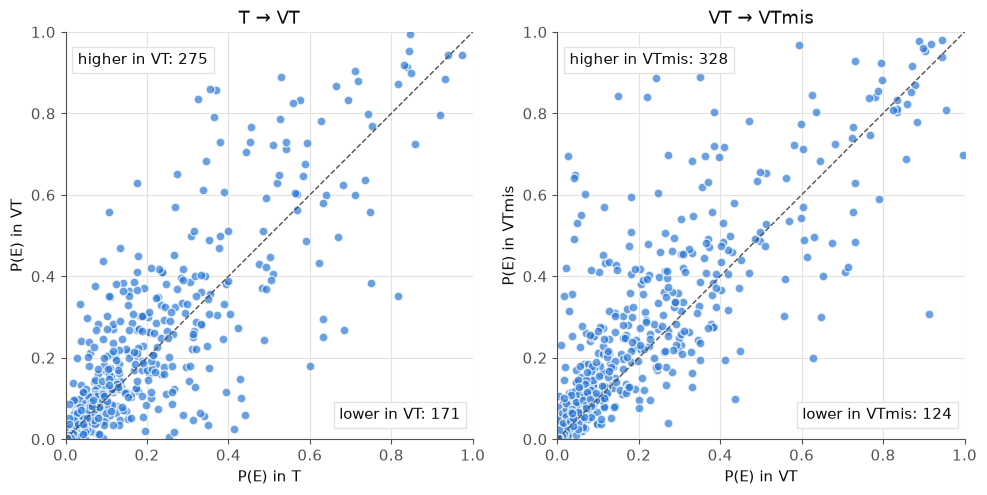

In [16]:
pE = df.pivot(index="question_id", columns="condition", values="p_E")
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (a, b) in zip(axes, [("T", "VT"), ("VT", "VTmis")]):
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
    ax.scatter(pE[a], pE[b], s=40, color=BLUE, alpha=0.7, edgecolor="white", linewidth=1)
    up, down = (pE[b] > pE[a] + 0.01).sum(), (pE[b] < pE[a] - 0.01).sum()
    ax.text(0.03, 0.95, f"higher in {b}: {up}", transform=ax.transAxes, va="top", color=INK, bbox=dict(facecolor="white", edgecolor=GRID))
    ax.text(0.97, 0.05, f"lower in {b}: {down}", transform=ax.transAxes, ha="right", color=INK, bbox=dict(facecolor="white", edgecolor=GRID))
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xlabel=f"P(E) in {a}", ylabel=f"P(E) in {b}", title=f"{a} → {b}")
    ax.grid(axis="both", color=GRID)
fig.tight_layout()
fig.savefig(FIGURES / "p_E_per_question.png", dpi=200)
plt.show()

#### 4. Where the answers move

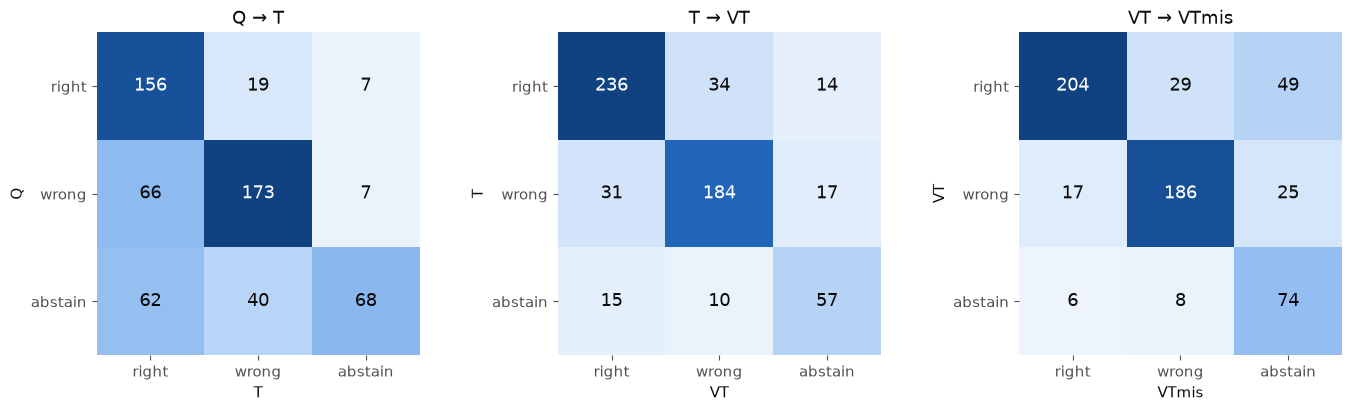

In [17]:
from matplotlib.colors import LinearSegmentedColormap

blues = LinearSegmentedColormap.from_list("blues", ["#f5f9fe", "#9ec5f4", "#2a78d6", "#104281"])
outcome = df.pivot(index="question_id", columns="condition", values="outcome")
labels = ["right", "wrong", "abstain"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (a, b) in zip(axes, [("Q", "T"), ("T", "VT"), ("VT", "VTmis")]):
    table = pd.crosstab(outcome[a], outcome[b]).reindex(index=labels, columns=labels, fill_value=0)
    ax.imshow(table.values, cmap=blues, vmin=0, vmax=table.values.max())
    for i in range(3):
        for j in range(3):
            n = table.values[i, j]
            ax.text(j, i, n, ha="center", va="center", fontsize=13,
                    color="white" if n > table.values.max() * 0.55 else INK)
    ax.set(xticks=range(3), xticklabels=labels, yticks=range(3), yticklabels=labels,
           xlabel=b, ylabel=a, title=f"{a} → {b}")
    ax.grid(False)
    ax.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "outcome_transitions.png", dpi=200)
plt.show()

#### 5. Subgroups: visual-cue tag and clips without dialogue

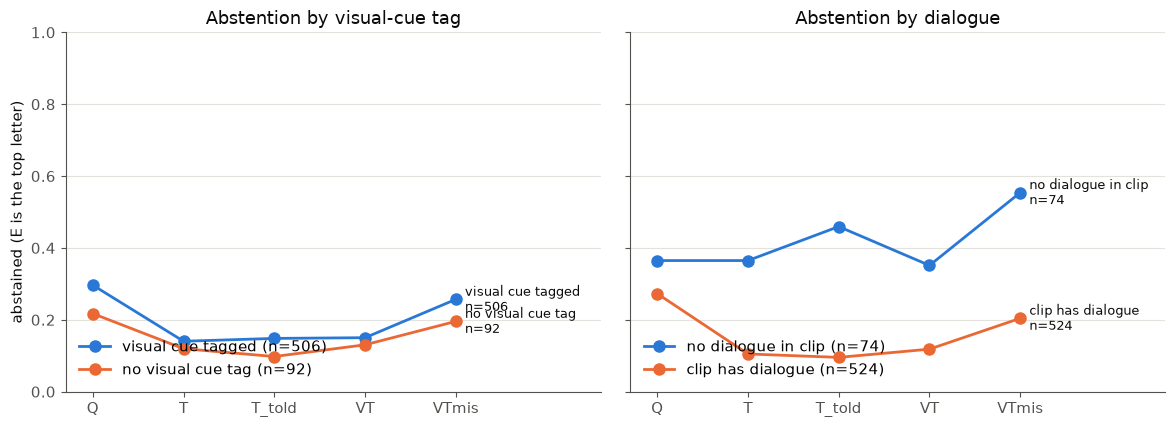

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, (column, names) in zip(axes, [("cue_visual_any", {True: "visual cue tagged", False: "no visual cue tag"}),
                                      ("no_dialogue", {False: "clip has dialogue", True: "no dialogue in clip"})]):
    for value, color in [(True, BLUE), (False, ORANGE)]:
        g = df[(df[column] == value) & df.condition.isin(with_e)]
        rate = g.groupby("condition").abstain.mean().reindex(with_e)
        n = g.question_id.nunique()
        ax.plot(range(len(with_e)), rate.values, "o-", color=color, lw=2, ms=8, label=f"{names[value]} (n={n})")
        ax.text(len(with_e) - 1 + 0.1, rate.values[-1], f"{names[value]}\nn={n}", va="center", color=INK, fontsize=9)
    ax.set(xticks=range(len(with_e)), xticklabels=with_e, ylim=(0, 1), xlim=(-0.3, len(with_e) + 0.6),
           title=f"Abstention by {'visual-cue tag' if column == 'cue_visual_any' else 'dialogue'}")
    ax.legend(loc="lower left")
axes[0].set_ylabel("abstained (E is the top letter)")
fig.tight_layout()
fig.savefig(FIGURES / "abstention_subgroups.png", dpi=200)
plt.show()

## Explanations

### Visual words in the explanations (keyword screen)

In [20]:
VISUAL_WORDS = ["face", "facial", "expression", "smile", "smiling", "frown", "eyes", "gaze", "tears", "crying",
                "body language", "posture", "gesture", "video", "visible"]
pattern = r"\b(?:" + "|".join(VISUAL_WORDS) + r")\b"
explanations["mentions_visual"] = explanations.explanation.str.contains(pattern, case=False)
display(explanations.groupby("condition").mentions_visual.mean().reindex(conditions).round(3))
explanations[(explanations.condition == "VTmis") & explanations.mentions_visual & (explanations.answer != "E")].head(10)

condition
Q_noE     0.104
Q         0.117
T         0.114
T_told    0.152
VT        0.227
VTmis     0.204
Name: mentions_visual, dtype: float64

,order,question_id,movie_title,question,condition,option_order,answer_shown,answer,confidence,p_E,explanation,evidence_answer,explanation_hit_limit,mentions_visual
5,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,VTmis,CBEDA,B,B,0.823633,0.420912,The man's expression and body language suggest he is worried about the possibility of not finding anyone inside.,video,False,True
101,16,5Ednd,THE FORFEIT,How is the man feeling as he knocks on the front door?,VTmis,CABDE,D,D,0.813927,0.138133,The man's body language and facial expression suggest that he is feeling nervous as he knocks on the front door.,video,False,True
131,21,4miKG,METROLAND,"How does the woman feel after telling the man to ""Act calm""?",VTmis,BACED,C,C,0.950542,0.487322,The woman's facial expression and body language suggest she is feeling nervous.,video,False,True
137,22,UoFUT,SOMETHING LIKE LONELINESS,What is the woman's emotional progression during the conversation?,VTmis,DECBA,D,B,0.435650,0.099220,The woman's emotional progression is inferred from her reactions and body language during the conversation.,transcript,False,True
167,27,0f5zd,HEAD ABOVE WATER,What does the man feel as the woman touches his face?,VTmis,BAECD,D,C,0.589206,0.103960,The man's expression and body language suggest he feels remorse and care for the woman.,transcript,False,True
215,35,tWgjm,GET READY WITH ME,Why is the man in olive green seated in front of the desktop moving his cursor between video thumbnails without clicking any of them?\n,VTmis,EACBD,B,A,0.959452,0.024931,"The man is overwhelmed by the day's events and struggles to commit to any video, revealing his inner turmoil.",transcript,False,True
251,41,7n_W8,THE ARK,What is the woman feeling in this situation?,VTmis,EDBAC,B,D,0.654994,0.127513,The woman's expression and body language suggest she is feeling regret and paranoia.,transcript,False,True
293,48,_aNhQ,ITALIAN MIRACLE,What is the woman feeling when she smiles?,VTmis,BCAED,A,B,0.482394,0.325416,"The woman is smiling nervously, trying to hide her true feelings.",both,False,True
323,53,WKjMC,MARYAM JOON,How does the young woman feel when she looks at the photo of her mother?,VTmis,CAEBD,D,B,0.981012,0.198743,The young woman's expression and the context of the scene suggest that she is sad about her mother's passing.,both,False,True
341,56,ZNtEo,BUD,What might be the reason the woman is filming the man?,VTmis,ABDCE,B,B,0.827622,0.089954,The woman's expression and the context suggest she disapproves of the man's actions.,transcript,False,True


#### 6. What the explanations talk about (keyword screens)

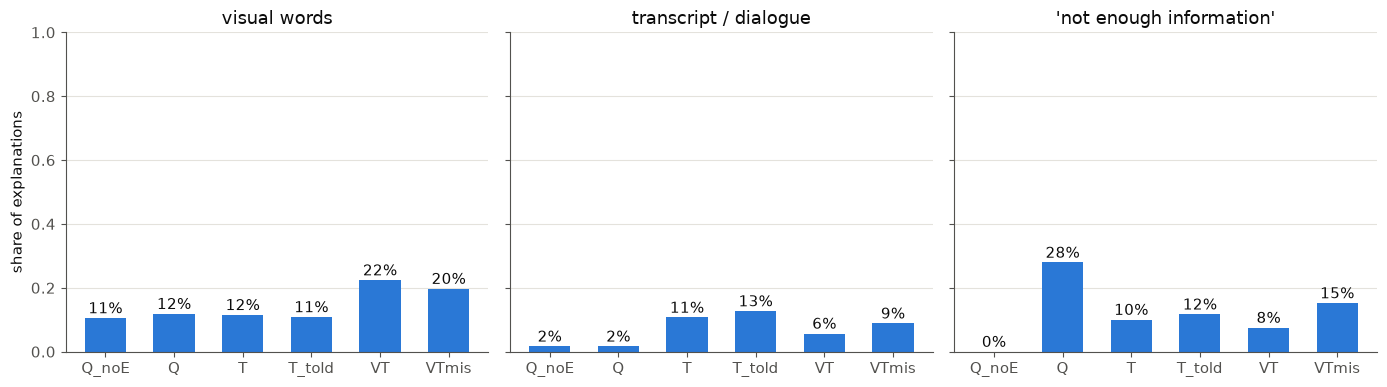

In [21]:
screens = {
    "visual words": r"\b(?:face|facial|expression|smil\w*|frown\w*|eyes|gaze|tears|cry\w*|body language|posture|gesture\w*)\b",
    "transcript / dialogue": r"\b(?:transcript|dialogue|says|said)\b",
    "'not enough information'": r"does not provide|not enough|cannot be determined|impossible to determine|no (?:information|dialogue|context)",
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (title, pattern) in zip(axes, screens.items()):
    share = explanations.explanation.str.contains(pattern, case=False).groupby(explanations.condition).mean().reindex(conditions)
    ax.bar(conditions, share.values, color=BLUE, width=0.6)
    for i, v in enumerate(share.values):
        ax.text(i, v + 0.015, f"{v:.0%}", ha="center", color=INK)
    ax.set(title=title, ylim=(0, 1))
axes[0].set_ylabel("share of explanations")
fig.tight_layout()
fig.savefig(FIGURES / "explanation_screens.png", dpi=200)
plt.show()

## Told that a video exists (T_told vs T)

Abstention in T and T_told, split by whether the video changed the answer (VT vs T).

In [22]:
if {"T", "T_told", "VT"} <= set(conditions):
    answers = df.pivot(index="question_id", columns="condition", values="answer")
    video_mattered = (answers["VT"] != answers["T"]).rename("video_mattered")
    told = df[df.condition.isin(["T", "T_told"])].merge(video_mattered, left_on="question_id", right_index=True)
    display(told.pivot_table(index="video_mattered", columns="condition", values=["abstain", "p_E"], aggfunc="mean").round(3))
    print("questions per group:", video_mattered.value_counts().to_dict())

abstain           p_E       
condition            T T_told      T T_told
video_mattered                             
False            0.128  0.121  0.155  0.162
True             0.164  0.197  0.206  0.217

questions per group: {False: 446, True: 152}


## Evidence question (branch B)

In [23]:
evidence_names = list(EVIDENCE)
display(pd.crosstab(df.condition, df.evidence_answer, normalize="index")
        .reindex(index=conditions, columns=evidence_names, fill_value=0).round(3))
display(pd.crosstab([df.condition, df.abstain], df.evidence_answer, normalize="index")
        .reindex(columns=evidence_names, fill_value=0).round(3))
claims_video = df.evidence_answer.isin(["video", "both"])
print("claimed a video:", claims_video.groupby(df.condition).mean().reindex(conditions).round(3).to_dict())
print("mean evidence_mass_on_letters:", round(df.evidence_mass_on_letters.mean(), 3))

evidence_answer,nothing,transcript,video,both
condition,,,,
Q_noE,0.371,0.443,0.161,0.025
Q,0.634,0.254,0.110,0.002
T,0.002,0.992,0.002,0.005
T_told,0.003,0.995,0.002,0.000
VT,0.023,0.569,0.176,0.232
VTmis,0.047,0.635,0.144,0.174


evidence_answer    nothing  transcript  video   both
condition abstain                                   
Q         False      0.521       0.334  0.143  0.002
          True       0.918       0.053  0.029  0.000
Q_noE     False      0.371       0.443  0.161  0.025
T         False      0.000       1.000  0.000  0.000
          True       0.012       0.939  0.012  0.037
T_told    False      0.000       0.998  0.002  0.000
          True       0.024       0.976  0.000  0.000
VT        False      0.000       0.602  0.171  0.227
          True       0.159       0.375  0.205  0.261
VTmis     False      0.000       0.698  0.138  0.164
          True       0.189       0.446  0.162  0.203

claimed a video: {'Q_noE': 0.186, 'Q': 0.112, 'T': 0.007, 'T_told': 0.002, 'VT': 0.408, 'VTmis': 0.318}
mean evidence_mass_on_letters: 1.0


## Option position

In [24]:
e_conditions = [c for c in conditions if c != "Q_noE"]
df["e_shown_as"] = df.option_order.str.find("E").map(dict(enumerate(SHOWN)))
display(df[df.condition.isin(e_conditions)]
        .pivot_table(index="condition", columns="e_shown_as", values="abstain", aggfunc="mean")
        .reindex(e_conditions).round(3))
display(pd.crosstab(df.condition, df.answer_shown, normalize="index").reindex(conditions).round(3))

e_shown_as,A,B,C,D,E
condition,,,,,
Q,0.206,0.406,0.328,0.341,0.150
T,0.118,0.189,0.185,0.181,0.023
T_told,0.118,0.179,0.185,0.196,0.030
VT,0.098,0.245,0.185,0.181,0.038
VTmis,0.216,0.349,0.336,0.304,0.053


answer_shown,A,B,C,D,E
condition,,,,,
Q_noE,0.236,0.274,0.251,0.239,0.000
Q,0.201,0.253,0.209,0.214,0.124
T,0.222,0.234,0.227,0.199,0.117
T_told,0.216,0.222,0.229,0.207,0.125
VT,0.216,0.253,0.221,0.201,0.110
VTmis,0.204,0.258,0.231,0.229,0.079


## Run time

In [25]:
seconds = df.score_seconds + df.explain_seconds + df.evidence_seconds
display(seconds.groupby(df.condition).mean().reindex(conditions).round(1).rename("seconds per question"))
print(f"{seconds.sum() / 3600:.1f} GPU-hours for {df.question_id.nunique()} questions (model loading not included)")

condition
Q_noE     0.9
Q         0.8
T         0.9
T_told    0.9
VT        9.8
VTmis     9.8
Name: seconds per question, dtype: float64

3.8 GPU-hours for 598 questions (model loading not included)


## Additional tests

In [26]:
from scipy.stats import binomtest, chi2_contingency, chisquare, mannwhitneyu

abstained = df.pivot(index="question_id", columns="condition", values="abstain")
for condition in e_conditions:
    lo, hi = wilson(abstained[condition].sum(), len(abstained))
    print(f"{condition:7} abstained {abstained[condition].mean():.1%}  95% CI [{lo:.1%}, {hi:.1%}]")
print()
for a, b in [("Q", "T"), ("T", "T_told"), ("T", "VT"), ("VT", "VTmis"), ("T", "VTmis")]:
    start = int((~abstained[a] & abstained[b]).sum())
    stop = int((abstained[a] & ~abstained[b]).sum())
    print(f"{a} -> {b}: {start} start abstaining, {stop} stop; exact McNemar p = {binomtest(start, start + stop).pvalue:.2g}")

Q       abstained 28.4%  95% CI [25.0%, 32.2%]
T       abstained 13.7%  95% CI [11.2%, 16.7%]
T_told  abstained 14.0%  95% CI [11.5%, 17.1%]
VT      abstained 14.7%  95% CI [12.1%, 17.8%]
VTmis   abstained 24.7%  95% CI [21.5%, 28.4%]

Q -> T: 14 start abstaining, 102 stop; exact McNemar p = 1.1e-17
T -> T_told: 11 start abstaining, 9 stop; exact McNemar p = 0.82
T -> VT: 31 start abstaining, 25 stop; exact McNemar p = 0.5
VT -> VTmis: 74 start abstaining, 14 stop; exact McNemar p = 5.1e-11
T -> VTmis: 73 start abstaining, 7 stop; exact McNemar p = 5.8e-15


In [27]:
pE = df.pivot(index="question_id", columns="condition", values="p_E")
answers = df.pivot(index="question_id", columns="condition", values="answer")
video_mattered = answers["VT"] != answers["T"]
rise = pE["T_told"] - pE["T"]
print(f"P(E) rise T -> T_told: video mattered {rise[video_mattered].mean():+.3f} (n = {video_mattered.sum()}), "
      f"did not {rise[~video_mattered].mean():+.3f} (n = {(~video_mattered).sum()}); "
      f"Mann-Whitney p = {mannwhitneyu(rise[video_mattered], rise[~video_mattered]).pvalue:.2g}")

P(E) rise T -> T_told: video mattered +0.011 (n = 152), did not +0.007 (n = 446); Mann-Whitney p = 0.14


In [28]:
for condition in e_conditions:
    g = df[df.condition == condition]
    p = chi2_contingency(pd.crosstab(g.e_shown_as, g.abstain))[1]
    print(f"abstention vs letter of 'Cannot tell', {condition}: chi-square p = {p:.2g}")
letters = df[df.condition == "Q_noE"].answer_shown.value_counts().reindex(["A", "B", "C", "D"])
print(f"Q_noE answers by shown letter: {letters.to_dict()}; chi-square vs equal p = {chisquare(letters).pvalue:.2g}")

abstention vs letter of 'Cannot tell', Q: chi-square p = 3.6e-05
abstention vs letter of 'Cannot tell', T: chi-square p = 0.0002
abstention vs letter of 'Cannot tell', T_told: chi-square p = 0.00038
abstention vs letter of 'Cannot tell', VT: chi-square p = 4.1e-05
abstention vs letter of 'Cannot tell', VTmis: chi-square p = 2.7e-08
Q_noE answers by shown letter: {'A': 141, 'B': 164, 'C': 150, 'D': 143}; chi-square vs equal p = 0.54


In [29]:
told = df[df.condition == "T_told"]
mentions_video = told.explanation.str.contains(r"\bvideo", case=False)
print(f"T_told explanations mentioning the video: {mentions_video.mean():.1%} "
      f"(abstentions {mentions_video[told.abstain].mean():.1%}, answers {mentions_video[~told.abstain].mean():.1%})")

T_told explanations mentioning the video: 6.5% (abstentions 31.0%, answers 2.5%)
